In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier



In [3]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")



In [4]:
df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop(columns=["target"])
y = df["target"].astype(int)

# Keep numeric columns
X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna(axis=1, how="all")

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (302, 13)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)



In [6]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)



In [7]:
model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_imputed, y_train)

test_probabilities = model.predict_proba(X_test_imputed)[:, 1]

test_predictions = (
    test_probabilities >= 0.50
).astype(int)

print("Model training and prediction completed.")

Model training and prediction completed.


In [8]:
results_df = X_test.copy()

results_df["Actual"] = np.array(y_test)
results_df["Predicted"] = test_predictions
results_df["Probability"] = test_probabilities

results_df["Error_Type"] = "Correct"

results_df.loc[
    (results_df["Actual"] == 0) &
    (results_df["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

results_df.loc[
    (results_df["Actual"] == 1) &
    (results_df["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

error_df = results_df[
    results_df["Error_Type"] != "Correct"
].copy()

false_positives = error_df[
    error_df["Error_Type"] == "False Positive"
].copy()

false_negatives = error_df[
    error_df["Error_Type"] == "False Negative"
].copy()

print("Total test cases:", len(results_df))
print("Total errors:", len(error_df))
print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

display(error_df.head(10))

Total test cases: 61
Total errors: 14
False positives: 7
False negatives: 7


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Probability,Error_Type
65,59,1,3,170,288,0,0,159,0,0.2,1,0,3,0,1,0.626424,False Positive
58,67,1,2,152,212,0,0,150,0,0.8,1,0,3,0,1,0.748912,False Positive
42,61,0,0,130,330,0,0,169,0,0.0,2,0,2,0,1,0.860431,False Positive
292,61,1,2,150,243,1,1,137,1,1.0,1,0,2,1,0,0.421879,False Negative
258,38,1,3,120,231,0,1,182,1,3.8,1,0,3,0,1,0.697987,False Positive
377,64,0,0,130,303,0,1,122,0,2.0,1,2,2,1,0,0.225531,False Negative
111,53,1,0,142,226,0,0,111,1,0.0,2,0,3,1,0,0.290890,False Negative
495,59,1,0,135,234,0,1,161,0,0.5,1,0,3,1,0,0.427098,False Negative
137,64,0,0,180,325,0,1,154,1,0.0,2,0,2,1,0,0.412972,False Negative
35,46,1,2,150,231,0,1,147,0,3.6,1,0,2,0,1,0.698076,False Positive


In [9]:
feature_columns = X.columns.tolist()

if len(error_df) >= 2:

    error_features = error_df[feature_columns].copy()

    error_features = pd.DataFrame(
        imputer.transform(error_features),
        columns=feature_columns,
        index=error_features.index
    )

    train_means = X_train_imputed.mean(axis=0)
    train_stds = X_train_imputed.std(axis=0)

    train_stds[train_stds == 0] = 1

    error_scaled = (
        error_features.to_numpy() - train_means
    ) / train_stds

    print("Error cases prepared for clustering.")
    print("Number of error cases:", len(error_scaled))

else:
    print("Not enough error cases to perform clustering.")

Error cases prepared for clustering.
Number of error cases: 14


In [10]:
def manual_kmeans(data, k=2, max_iterations=100, random_state=42):

    data = np.asarray(data, dtype=float)

    if len(data) < k:
        raise ValueError("Number of samples must be at least k.")

    rng = np.random.default_rng(random_state)

    initial_indices = rng.choice(
        len(data),
        size=k,
        replace=False
    )

    centroids = data[initial_indices].copy()

    for iteration in range(max_iterations):

        distances = np.sqrt(
            np.sum(
                (data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
                axis=2
            )
        )

        labels = np.argmin(distances, axis=1)

        new_centroids = centroids.copy()

        for cluster in range(k):

            cluster_points = data[labels == cluster]

            if len(cluster_points) > 0:
                new_centroids[cluster] = cluster_points.mean(axis=0)

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return labels, centroids


if len(error_df) >= 2:

    number_of_clusters = min(3, len(error_df))

    cluster_labels, cluster_centers = manual_kmeans(
        error_scaled,
        k=number_of_clusters
    )

    error_df["Cluster"] = cluster_labels

    print("Manual K-means clustering completed.")
    print("\nCluster counts:")
    print(error_df["Cluster"].value_counts().sort_index())

else:
    error_df["Cluster"] = -1
    print("Clustering skipped because there are fewer than two errors.")

Manual K-means clustering completed.

Cluster counts:
Cluster
0    3
1    8
2    3
Name: count, dtype: int64


In [11]:
if len(error_df) >= 2:

    cluster_summary = error_df.groupby("Cluster").agg(
        Total_Errors=("Error_Type", "count"),
        False_Positives=(
            "Error_Type",
            lambda values: (values == "False Positive").sum()
        ),
        False_Negatives=(
            "Error_Type",
            lambda values: (values == "False Negative").sum()
        ),
        Average_Probability=("Probability", "mean")
    )

    print("ERROR CLUSTER SUMMARY")
    display(cluster_summary)

    cluster_feature_summary = error_df.groupby("Cluster")[
        feature_columns
    ].mean()

    print("\nAVERAGE FEATURE VALUES BY CLUSTER")
    display(cluster_feature_summary)

else:
    cluster_summary = pd.DataFrame()
    cluster_feature_summary = pd.DataFrame()

ERROR CLUSTER SUMMARY


,Total_Errors,False_Positives,False_Negatives,Average_Probability
Cluster,,,,
0,3,2,1,0.540531
1,8,4,4,0.496869
2,3,1,2,0.454878



AVERAGE FEATURE VALUES BY CLUSTER


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
Cluster,,,,,,,,,,,,,
0,49.333333,0.666667,1.666667,133.333333,255.000000,0.000000,1.000000,150.333333,0.333333,3.133333,1.000000,0.666667,2.333333
1,58.250000,0.875000,1.000000,136.750000,249.500000,0.000000,0.375000,142.500000,0.375000,0.387500,1.500000,0.375000,2.625000
2,64.333333,0.666667,1.333333,170.000000,280.666667,0.666667,0.666667,147.000000,1.000000,0.866667,1.333333,0.000000,2.333333


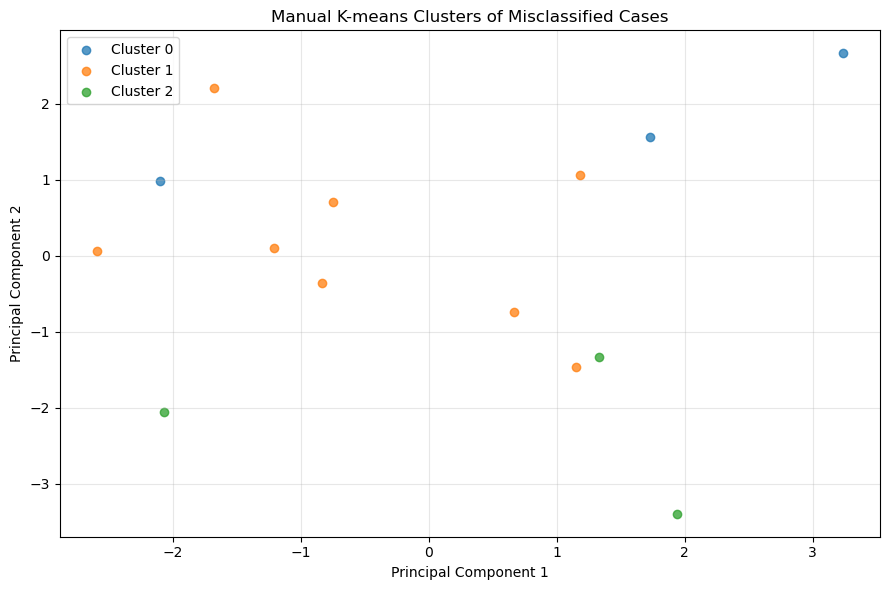

In [12]:
if len(error_df) >= 2:

    centered_data = error_scaled - error_scaled.mean(axis=0)

    U, S, Vt = np.linalg.svd(
        centered_data,
        full_matrices=False
    )

    number_of_components = min(2, Vt.shape[0])

    reduced_data = centered_data @ Vt[:number_of_components].T

    if number_of_components == 1:
        reduced_data = np.column_stack([
            reduced_data[:, 0],
            np.zeros(len(reduced_data))
        ])

    plt.figure(figsize=(9, 6))

    for cluster in sorted(error_df["Cluster"].unique()):

        mask = error_df["Cluster"].to_numpy() == cluster

        plt.scatter(
            reduced_data[mask, 0],
            reduced_data[mask, 1],
            label=f"Cluster {cluster}",
            alpha=0.75
        )

    plt.title("Manual K-means Clusters of Misclassified Cases")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("Not enough error cases to visualize clusters.")

In [13]:
Q1 = pd.DataFrame(
    X_train_imputed,
    columns=feature_columns
).quantile(0.25)

Q3 = pd.DataFrame(
    X_train_imputed,
    columns=feature_columns
).quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

test_feature_values = pd.DataFrame(
    X_test_imputed,
    columns=feature_columns,
    index=X_test.index
)

anomaly_flags = (
    (test_feature_values < lower_limit) |
    (test_feature_values > upper_limit)
)

anomaly_counts = anomaly_flags.sum(axis=1)

anomaly_df = results_df.copy()

anomaly_df["Anomaly_Count"] = anomaly_counts

error_anomalies = anomaly_df[
    (anomaly_df["Error_Type"] != "Correct") &
    (anomaly_df["Anomaly_Count"] > 0)
].copy()

print("Misclassified cases with at least one IQR anomaly:")
display(
    error_anomalies[
        ["Actual", "Predicted", "Error_Type", "Probability", "Anomaly_Count"]
    ]
)

print("\nTotal misclassified cases:", len(error_df))
print("Misclassified cases with anomalies:", len(error_anomalies))

Misclassified cases with at least one IQR anomaly:


,Actual,Predicted,Error_Type,Probability,Anomaly_Count
292,1,0,False Negative,0.421879,1
137,1,0,False Negative,0.412972,1
396,0,1,False Positive,0.529783,2



Total misclassified cases: 14
Misclassified cases with anomalies: 3


FEATURE ANOMALY REPORT


,Feature,Anomaly_Count,Anomaly_Percentage
0,fbs,12,19.672131
1,trestbps,3,4.918033
2,thalach,1,1.639344
3,ca,1,1.639344
4,age,0,0.000000
5,chol,0,0.000000
6,cp,0,0.000000
7,sex,0,0.000000
8,restecg,0,0.000000
9,exang,0,0.000000


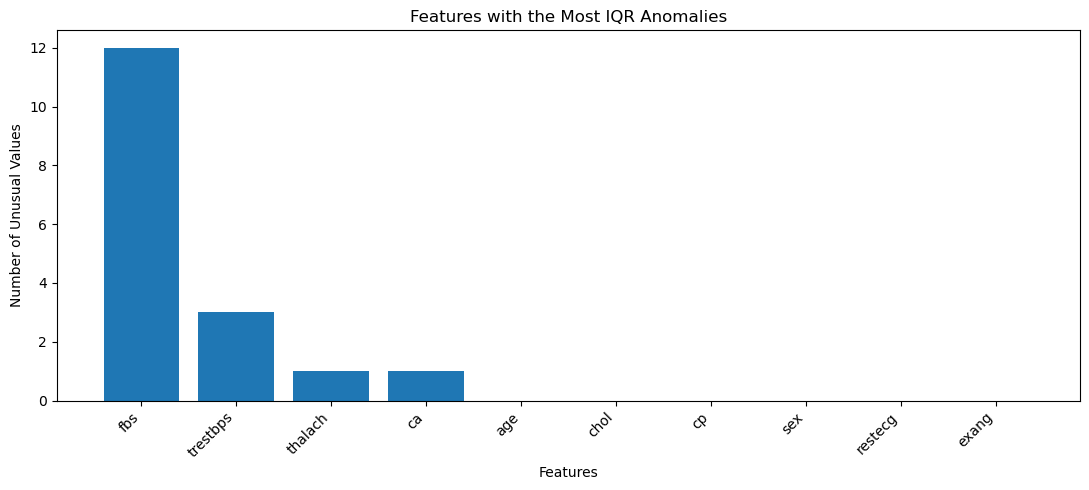

In [14]:
anomaly_feature_counts = anomaly_flags.sum().sort_values(
    ascending=False
)

anomaly_feature_report = pd.DataFrame({
    "Feature": anomaly_feature_counts.index,
    "Anomaly_Count": anomaly_feature_counts.values,
    "Anomaly_Percentage": (
        anomaly_feature_counts.values / len(anomaly_flags)
    ) * 100
})

print("FEATURE ANOMALY REPORT")
display(anomaly_feature_report)

plt.figure(figsize=(11, 5))

plt.bar(
    anomaly_feature_report["Feature"].head(10),
    anomaly_feature_report["Anomaly_Count"].head(10)
)

plt.title("Features with the Most IQR Anomalies")
plt.xlabel("Features")
plt.ylabel("Number of Unusual Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
subgroup_results = []

categorical_features = [
    col for col in feature_columns
    if X_train[col].nunique(dropna=True) <= 10
]

if "age" in feature_columns:

    age_edges = [0, 40, 50, 60, 70, 120]

    results_df["age_group"] = pd.cut(
        results_df["age"],
        bins=age_edges,
        labels=[
            "Below 40",
            "40-49",
            "50-59",
            "60-69",
            "70 and above"
        ],
        right=False
    )

    subgroup_features = categorical_features + ["age_group"]

else:
    subgroup_features = categorical_features


for feature in subgroup_features:

    for group_value, group_data in results_df.groupby(
        feature,
        observed=True,
        dropna=False
    ):

        actual_negative = group_data["Actual"] == 0
        actual_positive = group_data["Actual"] == 1

        group_size = len(group_data)
        errors = (group_data["Actual"] != group_data["Predicted"]).sum()

        fp_count = (
            (actual_negative) &
            (group_data["Predicted"] == 1)
        ).sum()

        fn_count = (
            (actual_positive) &
            (group_data["Predicted"] == 0)
        ).sum()

        fp_rate = (
            fp_count / actual_negative.sum()
            if actual_negative.sum() > 0 else np.nan
        )

        fn_rate = (
            fn_count / actual_positive.sum()
            if actual_positive.sum() > 0 else np.nan
        )

        subgroup_results.append({
            "Feature": feature,
            "Group": str(group_value),
            "Sample_Count": group_size,
            "Total_Errors": errors,
            "Error_Rate": errors / group_size,
            "False_Positives": fp_count,
            "False_Negatives": fn_count,
            "False_Positive_Rate": fp_rate,
            "False_Negative_Rate": fn_rate
        })


subgroup_df = pd.DataFrame(subgroup_results)

subgroup_df = subgroup_df.sort_values(
    "Error_Rate",
    ascending=False
)

print("SUBGROUP ERROR ANALYSIS")
display(
    subgroup_df[
        subgroup_df["Sample_Count"] >= 5
    ].round(3)
)

SUBGROUP ERROR ANALYSIS


,Feature,Group,Sample_Count,Total_Errors,Error_Rate,False_Positives,False_Negatives,False_Positive_Rate,False_Negative_Rate
5,cp,3,5,3,0.600,2,1,0.667,0.500
21,thal,3,19,7,0.368,4,3,0.267,0.750
25,age_group,60-69,21,7,0.333,3,4,0.200,0.667
13,slope,1,31,9,0.290,5,4,0.227,0.444
4,cp,2,14,4,0.286,3,1,0.600,0.111
15,ca,0,37,10,0.270,6,4,0.667,0.143
9,restecg,1,30,8,0.267,3,5,0.273,0.263
11,exang,1,27,7,0.259,2,5,0.111,0.556
1,sex,1,43,11,0.256,6,5,0.261,0.250
6,fbs,0,49,12,0.245,6,6,0.261,0.231


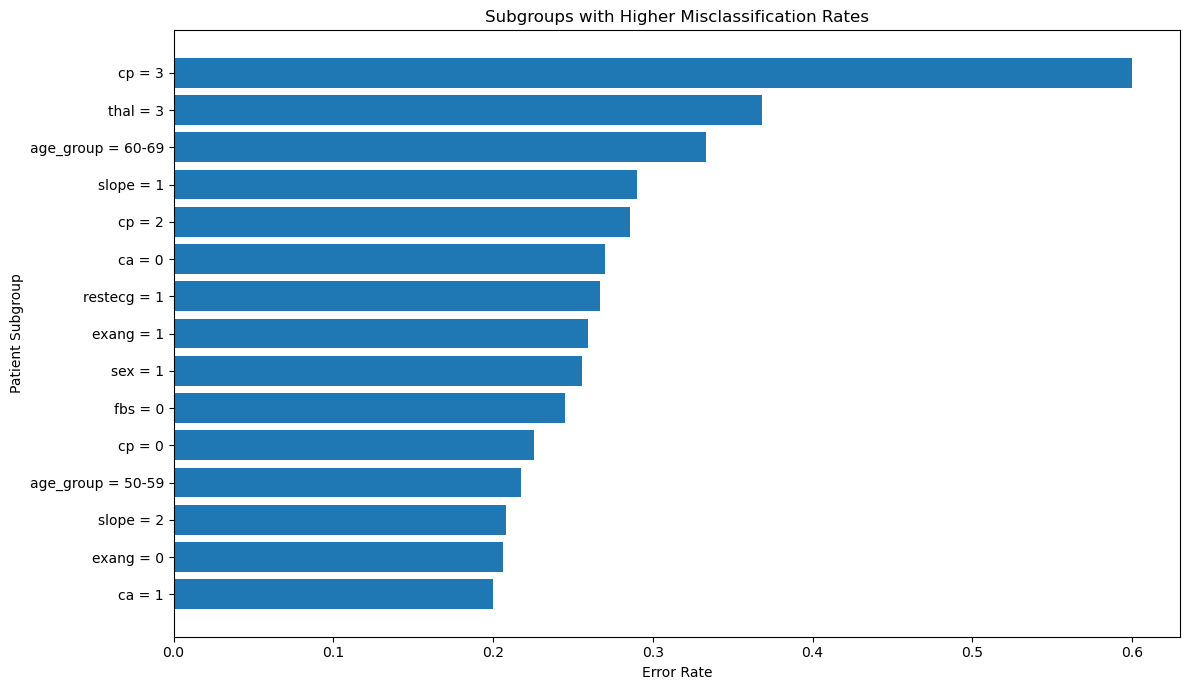

In [16]:
plot_subgroups = subgroup_df[
    subgroup_df["Sample_Count"] >= 5
].copy()

if len(plot_subgroups) > 0:

    plot_subgroups["Subgroup_Label"] = (
        plot_subgroups["Feature"].astype(str) +
        " = " +
        plot_subgroups["Group"].astype(str)
    )

    plot_data = plot_subgroups.head(15)

    plt.figure(figsize=(12, 7))

    plt.barh(
        plot_data["Subgroup_Label"],
        plot_data["Error_Rate"]
    )

    plt.title("Subgroups with Higher Misclassification Rates")
    plt.xlabel("Error Rate")
    plt.ylabel("Patient Subgroup")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

else:
    print("No subgroups have at least five test observations.")

In [17]:
root_cause_findings = []

if len(false_positives) > len(false_negatives):
    root_cause_findings.append(
        "False positives are more frequent than false negatives. "
        "Investigate whether the model is too likely to predict the positive class."
    )

elif len(false_negatives) > len(false_positives):
    root_cause_findings.append(
        "False negatives are more frequent than false positives. "
        "Investigate whether the model is missing positive cases."
    )

else:
    root_cause_findings.append(
        "False positives and false negatives occur in equal numbers."
    )


if len(error_df) > 0:

    anomaly_percentage = (
        len(error_anomalies) / len(error_df)
    ) * 100

    root_cause_findings.append(
        f"{anomaly_percentage:.1f}% of misclassified cases contain "
        "at least one feature outside the training-data IQR limits."
    )


if len(error_df) >= 2:

    largest_cluster = error_df["Cluster"].value_counts().idxmax()

    largest_cluster_count = (
        error_df["Cluster"].value_counts().max()
    )

    root_cause_findings.append(
        f"Cluster {largest_cluster} contains the largest number "
        f"of errors ({largest_cluster_count}). Examine its feature averages."
    )


eligible_subgroups = subgroup_df[
    subgroup_df["Sample_Count"] >= 5
]

if len(eligible_subgroups) > 0:

    highest_subgroup = eligible_subgroups.iloc[0]

    root_cause_findings.append(
        f"The highest observed subgroup error rate is for "
        f"{highest_subgroup['Feature']} = {highest_subgroup['Group']}, "
        f"with an error rate of "
        f"{highest_subgroup['Error_Rate']:.2%}."
    )

else:

    root_cause_findings.append(
        "There are not enough observations in the subgroups "
        "to identify a reliable subgroup error pattern."
    )


print("POSSIBLE ROOT-CAUSE FINDINGS\n")

for i, finding in enumerate(root_cause_findings, start=1):
    print(f"{i}. {finding}")

POSSIBLE ROOT-CAUSE FINDINGS

1. False positives and false negatives occur in equal numbers.
2. 21.4% of misclassified cases contain at least one feature outside the training-data IQR limits.
3. Cluster 1 contains the largest number of errors (8). Examine its feature averages.
4. The highest observed subgroup error rate is for cp = 3, with an error rate of 60.00%.


In [18]:
from datetime import datetime

report = []

report.append("# Misclassification Clustering and Root-Cause Analysis")
report.append("")
report.append("Generated: " + datetime.now().strftime("%Y-%m-%d %H:%M"))
report.append("")

report.append("## 1. Model Error Summary")
report.append(f"- Total test observations: {len(results_df)}")
report.append(f"- Total misclassified observations: {len(error_df)}")
report.append(f"- False positives: {len(false_positives)}")
report.append(f"- False negatives: {len(false_negatives)}")
report.append("")

report.append("## 2. Manual Clustering Results")
report.append("")

if len(cluster_summary) > 0:
    report.append(cluster_summary.to_string())
else:
    report.append("Clustering could not be performed.")

report.append("")

report.append("## 3. Anomaly Detection Results")
report.append("")
report.append(
    f"Misclassified cases containing at least one IQR anomaly: "
    f"{len(error_anomalies)}"
)
report.append("")
report.append(anomaly_feature_report.to_string(index=False))
report.append("")

report.append("## 4. Subgroup Analysis")
report.append("")

report.append(
    subgroup_df[
        subgroup_df["Sample_Count"] >= 5
    ].to_string(index=False)
)
report.append("")

report.append("## 5. Root-Cause Findings")
report.append("")

for finding in root_cause_findings:
    report.append("- " + finding)

report.append("")

report.append("## 6. Recommended Improvements")
report.append("")
report.append("- Collect more examples from underrepresented subgroups.")
report.append("- Review unusual patient records and check for data-entry errors.")
report.append("- Investigate whether correlated features affect model predictions.")
report.append("- Evaluate false-positive and false-negative rates separately.")
report.append("- Validate model performance using repeated stratified cross-validation.")
report.append("- Review subgroup findings with qualified healthcare professionals.")
report.append("- Reassess the classification threshold using validation data.")
report.append("")

report.append("## 7. Limitations")
report.append("")
report.append("- K-means clusters describe similarity, not medical diagnoses.")
report.append("- IQR anomalies are statistical observations, not necessarily incorrect data.")
report.append("- Small subgroup sizes can produce unstable error rates.")
report.append("- Observed associations do not prove the cause of model errors.")
report.append("- This model is for educational analysis, not clinical diagnosis.")
error_df.to_csv(
    "clustered_misclassified_examples.csv",
    index=False
)

false_positives.to_csv(
    "false_positive_cases.csv",
    index=False
)

false_negatives.to_csv(
    "false_negative_cases.csv",
    index=False
)

cluster_summary.to_csv(
    "error_cluster_summary.csv"
)

cluster_feature_summary.to_csv(
    "error_cluster_feature_summary.csv"
)

anomaly_feature_report.to_csv(
    "error_anomaly_feature_report.csv",
    index=False
)

error_anomalies.to_csv(
    "misclassified_anomaly_cases.csv",
    index=False
)


subgroup_df.to_csv(
    "subgroup_error_analysis.csv",
    index=False
)

print("All analysis files saved successfully.")
with open(
    "misclassification_root_cause_report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(report))

print("Root-cause analysis report created successfully.")
error_df.to_csv(
    "clustered_misclassified_examples.csv",
    index=False
)

false_positives.to_csv(
    "false_positive_cases.csv",
    index=False
)

false_negatives.to_csv(
    "false_negative_cases.csv",
    index=False
)

cluster_summary.to_csv(
    "error_cluster_summary.csv"
)

cluster_feature_summary.to_csv(
    "error_cluster_feature_summary.csv"
)

anomaly_feature_report.to_csv(
    "error_anomaly_feature_report.csv",
    index=False
)

error_anomalies.to_csv(
    "misclassified_anomaly_cases.csv",
    index=False
)

subgroup_df.to_csv(
    "subgroup_error_analysis.csv",
    index=False
)

print("All analysis files saved successfully.")

Root-cause analysis report created successfully.
